# IE0005 Mini-Project: Fake Jobs Listing Prediction
## Gyatt Damn:
  1. Lam Jun Heng Jerrick
  2. Darren Lee
  3. Chew Jia Hui
  4. Seetoh
  
Our dataset is from Kaggle: https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction

### 1) Installing The Essential Libraries

In [1]:
!pip install wordcloud

Importing the required libraries

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sb
import matplotlib.pyplot as plt

In [3]:
!pip install sklearn-pandas

In [4]:
## Importing Scikit-learn libraries for the models

import sklearn_pandas
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score ,confusion_matrix ,classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, classification_report, confusion_matrix, fbeta_score, precision_score, roc_curve, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve
from sklearn import metrics

In [5]:
!pip install nltk

In [6]:
## Importing natural language processing libraries

from wordcloud import WordCloud
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jerri\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 2) Exploratory Data Analysis

In [7]:
#Importing the file

data = pd.read_csv('fake_job_listings.csv')
data.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [8]:
## Data stats
data.describe()

,job_id,telecommuting,has_company_logo,has_questions,fraudulent
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,8940.500000,0.042897,0.795302,0.491723,0.048434
std,5161.655742,0.202631,0.403492,0.499945,0.214688
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4470.750000,0.000000,1.000000,0.000000,0.000000
50%,8940.500000,0.000000,1.000000,0.000000,0.000000
75%,13410.250000,0.000000,1.000000,1.000000,0.000000
max,17880.000000,1.000000,1.000000,1.000000,1.000000


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [10]:
data.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='object')

In [11]:
#Count the number of missing null values
data.isnull().sum()

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

In [12]:
data.shape

(17880, 18)

In [13]:
#Fill the missing Null values in the data with an empty string
data.fillna('',inplace=True)

In [14]:
#Delete the columns that are not being used
data.drop(['job_id' , 'salary_range' , 'telecommuting' , 'has_company_logo' , 'has_questions'] , axis = 1,inplace = True)
data.head()

,title,location,department,company_profile,description,requirements,benefits,employment_type,required_experience,required_education,industry,function,fraudulent
0,Marketing Intern,"US, NY, New York",Marketing,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,,Other,Internship,,,Marketing,0
1,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,Full-time,Not Applicable,,Marketing and Advertising,Customer Service,0
2,Commissioning Machinery Assistant (CMA),"US, IA, Wever",,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,,,,,,,0
3,Account Executive - Washington DC,"US, DC, Washington",Sales,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,Bill Review Manager,"US, FL, Fort Worth",,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [15]:
# Check for the number of fake jobs
data.groupby('fraudulent')['fraudulent'].count()

fraudulent
0    17014
1      866
Name: fraudulent, dtype: int64

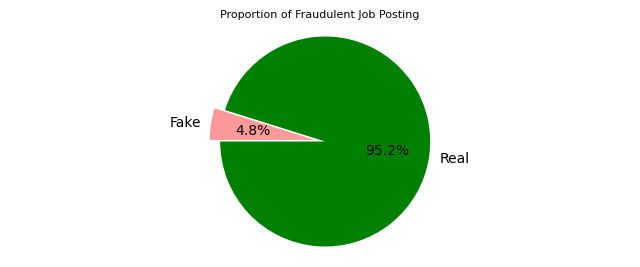

In [16]:
# Visualizing the data
labels = 'Real' ,'Fake'
colors = ['g', '#ff9999']

fraud = data.groupby('fraudulent').size()
explode =(0,0.1)

fig1 ,ax1 = plt.subplots(figsize =(8,3))
ax1.pie(fraud ,explode =explode, labels =labels, autopct ='%1.1f%%',startangle =180, colors = colors)

ax1.axis('equal')
plt.title("Proportion of Fraudulent Job Posting" ,size = 8)
plt.show()

The pie chart shows that fake job postings make up for about 5% of the total job postings.
But, the data is very unbalanced and is biased towards real jobs

In [17]:
# Job postings by country

def split(location):
    #separate the country from other location information
    #store in variable '1'
  l =location.split(',')
  return l[0]

data['country'] =data.location.apply(split) 

In [18]:
#calculate nuber of unique countries
data['country'].nunique()

91

In [19]:
# finding the top 10 countries which offer the most jobs
data['country'].value_counts()[:10]

country
US    10656
GB     2384
GR      940
CA      457
DE      383
        346
NZ      333
IN      276
AU      214
PH      132
Name: count, dtype: int64

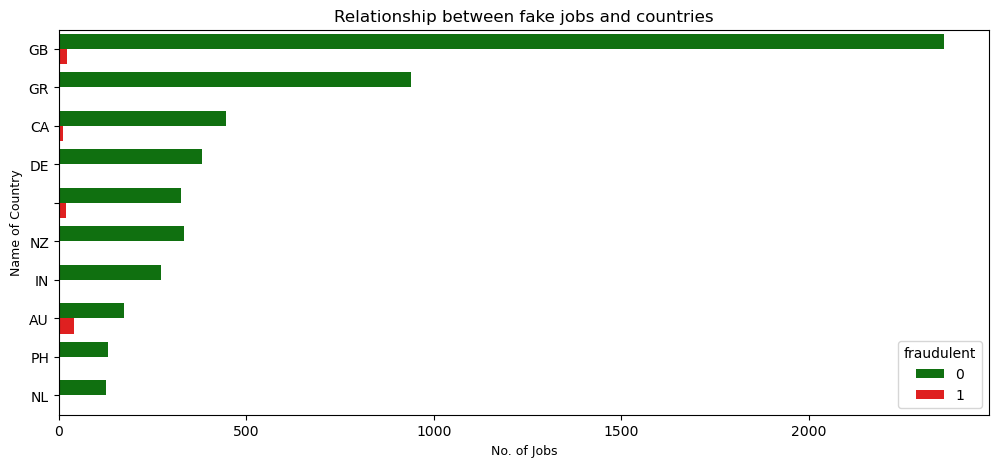

In [20]:
#Finding the relationship between fake jobs and countries

country = data[data['country'].notna()]

# Convert 'fraudulent' column to strings
country['fraudulent'] = country['fraudulent'].astype(str)

plt.figure(figsize=(12, 5))

custom_palette = ["g", "r"]

# Plot the countplot
sb.countplot(y='country', data=country, hue="fraudulent", order=data['country'].value_counts().iloc[1:11].index, palette=custom_palette)
plt.xticks(rotation=0)
title = 'Relationship between fake jobs and countries'
plt.ylabel('Name of Country', size=9)
plt.xlabel('No. of Jobs', size=9)
plt.title(title)

plt.show()

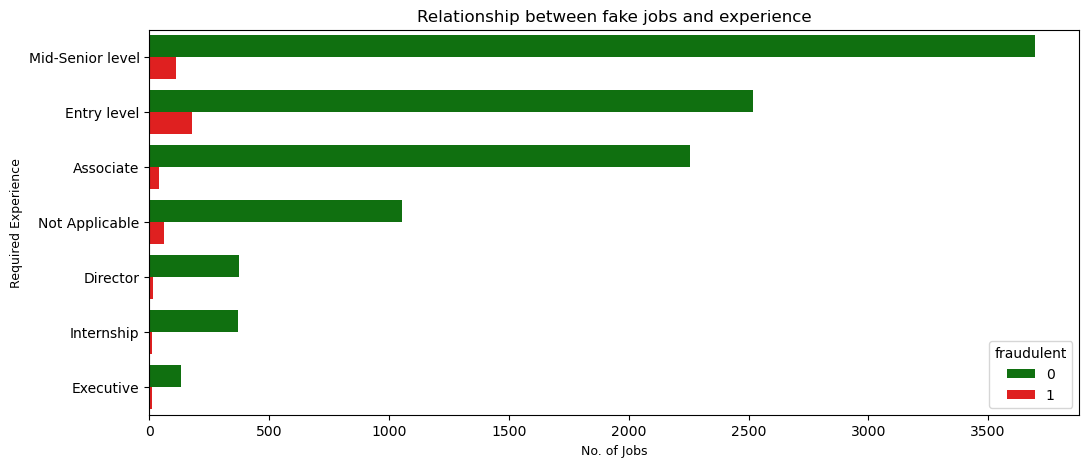

In [21]:
# Relationship between fake jobs and job experience

experience = data[data['required_experience'].notna()]

# Convert 'fraudulent' column to strings
experience['fraudulent'] = experience['fraudulent'].astype(str)

plt.figure(figsize=(12, 5))

custom_palette = ["g", "r"]

# Plot the countplot
sb.countplot(y='required_experience', data=experience, hue="fraudulent", order=data['required_experience'].value_counts().iloc[1:11].index, palette=custom_palette)

plt.xticks(rotation=0)
title = 'Relationship between fake jobs and experience'
plt.ylabel('Required Experience', size=9)
plt.xlabel('No. of Jobs', size=9)
plt.title(title)

plt.show()

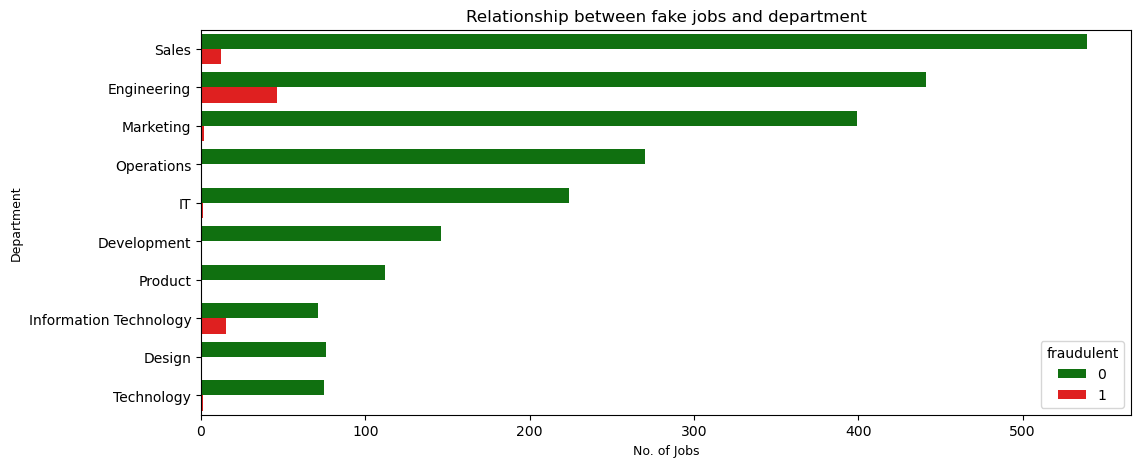

In [22]:
# Relationship between fake jobs and the department

department1 = data[data['department'].notna()]

# Convert 'fraudulent' column to strings
department1['fraudulent'] = department1['fraudulent'].astype(str)

plt.figure(figsize=(12, 5))

custom_palette = ["g", "r"]

sb.countplot(y='department', data=department1, hue="fraudulent", order=data['department'].value_counts().iloc[1:11].index, palette=custom_palette)

plt.xticks(rotation=0)
title = 'Relationship between fake jobs and department'
plt.ylabel('Department', size=9)
plt.xlabel('No. of Jobs', size=9)
plt.title(title)
plt.show()

#### Wordcloud Visualization

Wordcloud is a tool for us to see the 'important' words in terms of how often they appear. The more times the word appears, the more likely it shows us if the job listing is fake or not.

In [23]:
# The most common job titles in general
data.title.value_counts()[:10]

title
English Teacher Abroad                                311
Customer Service Associate                            146
Graduates: English Teacher Abroad (Conversational)    144
English Teacher Abroad                                 95
Software Engineer                                      86
English Teacher Abroad (Conversational)                83
Customer Service Associate - Part Time                 76
Account Manager                                        75
Web Developer                                          66
Project Manager                                        62
Name: count, dtype: int64

In [24]:
# Check which jobs are not fake
data[data.fraudulent == 0].title.value_counts()[:10]

title
English Teacher Abroad                                311
Customer Service Associate                            146
Graduates: English Teacher Abroad (Conversational)    144
English Teacher Abroad                                 95
Software Engineer                                      86
English Teacher Abroad (Conversational)                83
Customer Service Associate - Part Time                 76
Account Manager                                        73
Web Developer                                          66
Project Manager                                        62
Name: count, dtype: int64

In [25]:
# Check which jobs are fake
data[data.fraudulent == 1].title.value_counts()[:10]

title
Data Entry Admin/Clerical Positions - Work From Home                    21
Home Based Payroll Typist/Data Entry Clerks Positions Available         21
Cruise Staff Wanted *URGENT*                                            21
Customer Service Representative                                         17
Administrative Assistant                                                16
Home Based Payroll Data Entry Clerk Position - Earn $100-$200 Daily     12
Account Sales Managers $80-$130,000/yr                                  10
Network Marketing                                                       10
Payroll Clerk                                                           10
Payroll Data Coordinator Positions - Earn $100-$200 Daily               10
Name: count, dtype: int64

In [26]:
# This is to streamline the data processing for later, removing the initial colums used to create the "text" column

data['text'] = data['title'] + ' '+ data['location'] + ' ' + data['department'] + ' ' + data['company_profile'] + ' '+ data['description'] + ' ' + data['requirements'] + ' ' + data['benefits'] + ' ' + data['industry']

del data['title']
del data['location']
del data['department']
del data['company_profile']
del data['description']
del data['requirements']
del data['benefits']
del data['employment_type']
del data['required_experience']
del data['required_education']
del data['industry']
del data['function']
del data['country']

In [27]:
data.head()

,fraudulent,text
0,0,"Marketing Intern US, NY, New York Marketing We..."
1,0,"Customer Service - Cloud Video Production NZ, ..."
2,0,"Commissioning Machinery Assistant (CMA) US, IA..."
3,0,"Account Executive - Washington DC US, DC, Wash..."
4,0,"Bill Review Manager US, FL, Fort Worth SpotSo..."


In [28]:
data.shape

(17880, 2)

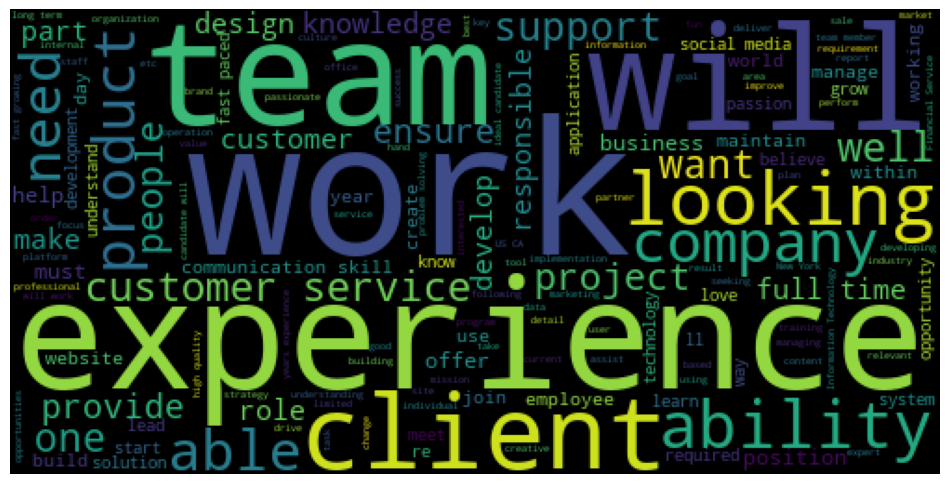

In [29]:
# Creating a wordcloud for all the words

all_words = ' '.join([text for text in data['text']])
wordcloud = WordCloud(width = 500 ,height = 250, max_font_size = 100).generate(all_words)

plt.figure(figsize =(12,8))
plt.imshow(wordcloud)

# ignore the grid and axis of the wordcloud
plt.axis('off')

plt.show()

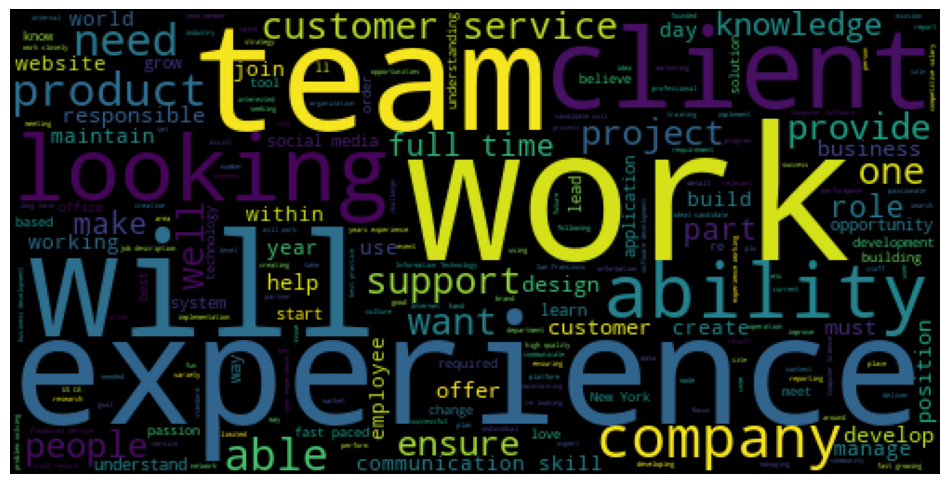

In [30]:
# Frequency of the word in real job listings

real_post = ' '.join([text for text in data['text'][data['fraudulent']==0]])
wordcloud1 = WordCloud(width = 500 ,height = 250, max_font_size = 100).generate(real_post)

plt.figure(figsize =(12,8))
plt.imshow(wordcloud1)

# Ignore the grid and axis of the wordcloud
plt.axis('off')

plt.show()

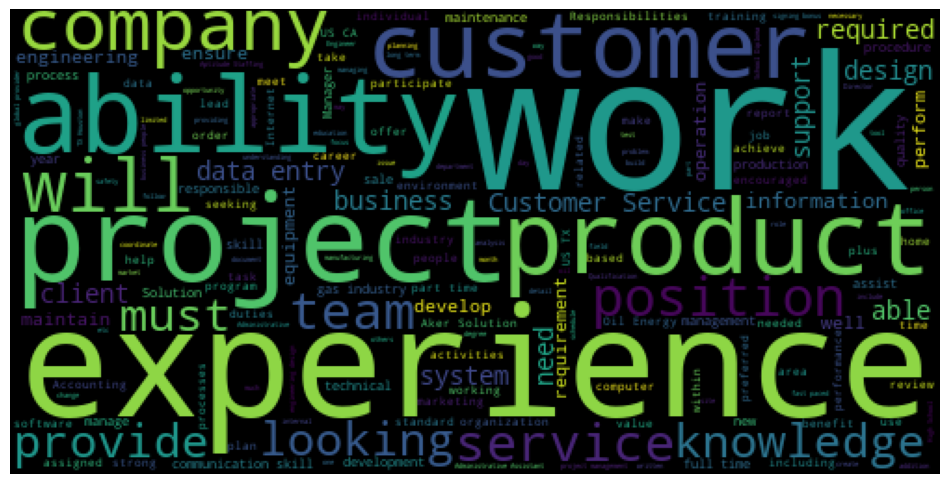

In [31]:
# Frequency of the word in fake job listings

fake_post = ' '.join([text for text in data['text'][data['fraudulent'] == 1]])
wordcloud2 = WordCloud(width = 500 ,height = 250, max_font_size = 100).generate(fake_post)

plt.figure(figsize =(12,8))
plt.imshow(wordcloud2)

# Ignore the grid and axis of the wordcloud
plt.axis('off')

plt.show()

## 3) Preprocessing Our Data

### Down Sampling Data

Down sampling our non-fraudulent data to enable a better training model

In [32]:
label='fraudulent'

g = data.groupby(label, group_keys=False)
balanced_data = pd.DataFrame(g.apply(lambda x: x.sample(g.size().min()))).reset_index(drop=True)
balanced_data.head()

C:\Users\jerri\AppData\Local\Temp\ipykernel_4956\3611987185.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  balanced_data = pd.DataFrame(g.apply(lambda x: x.sample(g.size().min()))).reset_index(drop=True)


,fraudulent,text
0,0,"Area Manager US, CA, Ontario Sales Solar elect..."
1,0,"Virality Code Ninja (Full-Stack Developer) GB,..."
2,0,Project Cost Control Staff Engineer - Cost Con...
3,0,"Virtualization/ Systems Engineer US, GA, Atlan..."
4,0,"Need Filenet consultants US, PA, harrisburg ..."


In [33]:
# Checking the number of fake and real job listings in this new downsized sample

balanced_data.groupby('fraudulent')['fraudulent'].count()

fraudulent
0    866
1    866
Name: fraudulent, dtype: int64

<Figure size 1200x500 with 0 Axes>

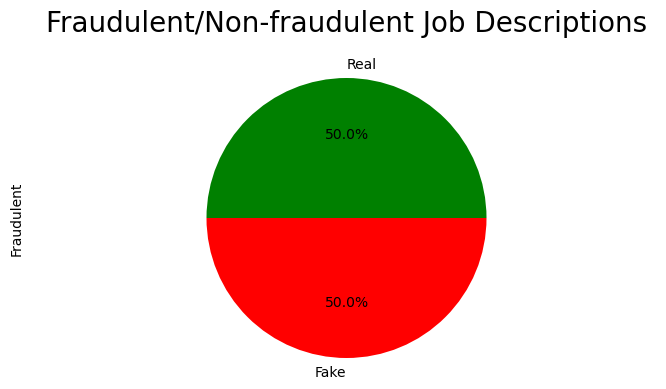

In [34]:
labels = 'Fake' ,'Real'
colors = ['#ff9999', '#66b3ff']

fraud = balanced_data.groupby('fraudulent').size()

plt.figure(figsize=(12,5))

custom_palette = ["r", "g"]

fig2 ,ax2 = plt.subplots(figsize =(8,4))
ax2.pie(fraud, labels =labels, autopct ='%1.1f%%',startangle =180, colors = custom_palette)

ax2.axis('equal')

plt.title('Fraudulent/Non-fraudulent Job Descriptions', size=20, y=1.08)
plt.ylabel("Fraudulent", labelpad=9)  
plt.show()

In [35]:
# Display the column's text
balanced_data['text'][0]

'Area Manager US, CA, Ontario Sales Solar electricity is the way of the future! \xa0We are focused on bringing solar to homeowners in a simple solution with no up-front cost to the customer. \xa0We are looking for talented and driven people to join our team and take their careers to the next level while growing our business into a national leader in solar energy development. \xa0Our culture is a fast paced, high growth, work hard, play hard environment that encourages collaboration. Your brighter future starts today. Suncrest is looking for driven Sales Representatives/Area Managers to engage homeowners for our solar program. You will be responsible for growing sales in your office and contributing to your team’s overall goals.\xa0Our Sales teams are made of high energy, highly driven reps with a passion for our mission – saving homeowners money and saving our planet’s natural resources. We are looking for motivated individuals who will add to our team. Knowledge and understanding of S

### "STOP WORDS" which refer to common words that are commonly filtered out/ignored when processing these column text. E.G (the, and, is, in, it).

In [36]:
print(stopwords.words("english"))

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [37]:
# Change the list to set and remove duplicates
stop_words = set(stopwords.words("english"))

In [38]:
# Make them lowercase
balanced_data['text'] = balanced_data['text'].apply(lambda x:x.lower())

In [39]:
# Remove the stop words
balanced_data['text'] = balanced_data['text'].apply(lambda x:''.join([word for word in x.split() if word not in (stop_words)]))

In [40]:
# After removing the stop words
balanced_data['text'][0]

'areamanagerus,ca,ontariosalessolarelectricitywayfuture!focusedbringingsolarhomeownerssimplesolutionup-frontcostcustomer.lookingtalenteddrivenpeoplejointeamtakecareersnextlevelgrowingbusinessnationalleadersolarenergydevelopment.culturefastpaced,highgrowth,workhard,playhardenvironmentencouragescollaboration.brighterfuturestartstoday.suncrestlookingdrivensalesrepresentatives/areamanagersengagehomeownerssolarprogram.responsiblegrowingsalesofficecontributingteam’soverallgoals.salesteamsmadehighenergy,highlydrivenrepspassionmission–savinghomeownersmoneysavingplanet’snaturalresources.lookingmotivatedindividualsaddteam.knowledgeunderstandingsuncrest’ssystemsofferingsgaincustomersdirectmarketingconstantlybuildsalessalespipelinereferralsdirectsellingeffortsmaintaincustomerrelationshipsensuretopcustomersatisfactionaddofficeteamhighenergy,drive,motivationsucceedtopindustrycommissionspaidtrainingbonuseseligibilityequitypoolfun,fast-pacedculturefullbenefits(after90dayscontracting)quickadvancementop

## 4) Training The Model :)

### The data is unstructured, hence we have to use classification models to work with the data.

For this part, we can try to use different classification models to see which one has the best results.
The models we use are:
1) Naive Bayes
2) Random Forest Algorithm

In [41]:
# Divide the dataset into the train and test set respectively
X_train,X_test ,y_train,y_test = train_test_split(balanced_data.text, balanced_data.fraudulent ,test_size = 0.4)

In [42]:
print(X_train.shape) #0.6 for the train set and 0.4 for the test set
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1039,)
(1039,)
(693,)
(693,)


In [43]:
vect = CountVectorizer()
vect.fit(X_train)

CountVectorizer()

from sklearn.feature_extraction.text import CountVectorizer

## Sample documents
documents = [
    "This is the first document.",
    "This document is the second document.",
    "And this is the third one.",
    "Is this the first document?",
]

## Create a Count Vectorizer
vectorizer = CountVectorizer()

## Fit and transform the documents to create a document-term matrix (DTM)
X = vectorizer.fit_transform(documents)

## Convert the DTM into an array for easier viewing
dtm_array = X.toarray()

## Get the feature names
feature_names = vectorizer.get_feature_names_out()

## Display the DTM
print(dtm_array)
print("Feature names:", feature_names)



In [44]:
# Convert our text data into a vector
X_train_dtm = vect.transform(X_train)

In [45]:
X_train_dtm

<1039x33791 sparse matrix of type '<class 'numpy.int64'>'
	with 56938 stored elements in Compressed Sparse Row format>

In [46]:
# Using Naive Bayes Classificaiton
X_test_dtm = vect.transform(X_test)
X_test_dtm

<693x33791 sparse matrix of type '<class 'numpy.int64'>'
	with 20666 stored elements in Compressed Sparse Row format>

In [47]:
nb = MultinomialNB()
nb.fit(X_train_dtm, y_train)

MultinomialNB()

In [48]:
y_pred_train_nb = nb.predict(X_train_dtm)

In [49]:
accuracy_score(y_train,y_pred_train_nb)

0.9990375360923965

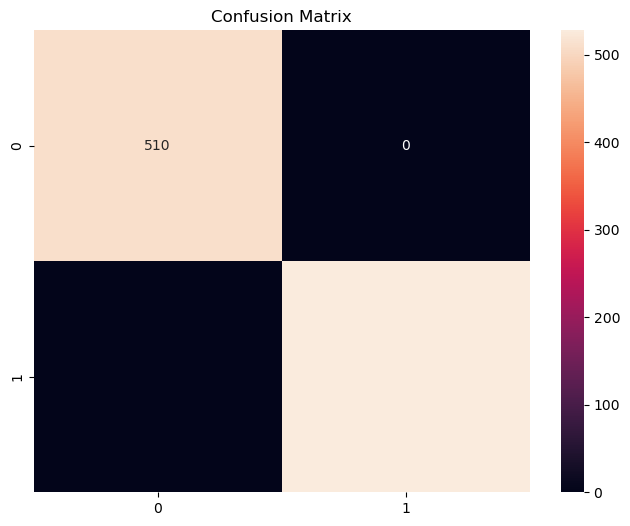

In [50]:
# Compute confusion matrix
cm = confusion_matrix(y_train, y_pred_train_nb)

# Set up the heatmap
plt.figure(figsize=(8, 6))
sb.heatmap(cm, annot=True, fmt="d")

# Add title
plt.title('Confusion Matrix')

# Display the plot
plt.show()

In [51]:
y_pred_nb = nb.predict(X_test_dtm)

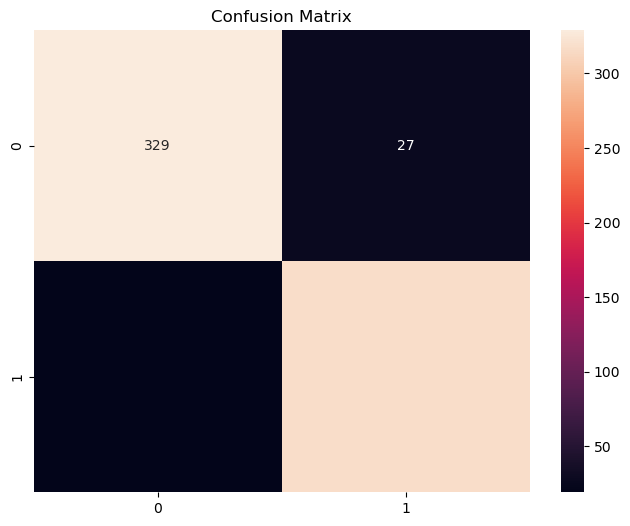

In [52]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_nb)

# Set up the heatmap
plt.figure(figsize=(8, 6))
sb.heatmap(cm, annot=True, fmt="d")

# Add title
plt.title('Confusion Matrix')

# Display the plot
plt.show()

In [53]:
# Results of the Naive Bayes Classifier
print("MultinomialNB Accuracy:", accuracy_score(y_test, y_pred_nb))
print("MultinomialNB F2 score:", fbeta_score(y_test, y_pred_nb, average='binary', beta=2))
print('MultinomialNB ROC AUC Score', roc_auc_score(y_test, y_pred_nb))

MultinomialNB Accuracy: 0.9336219336219336
MultinomialNB F2 score: 0.9391612522150029
MultinomialNB ROC AUC Score 0.9338887407061648


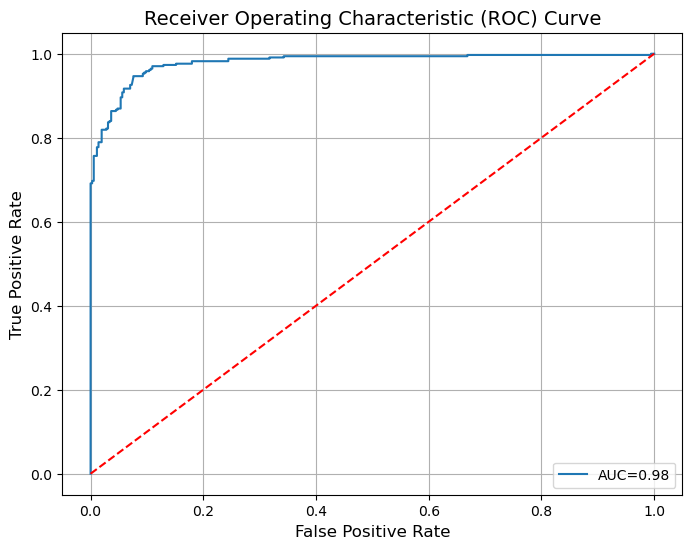

In [54]:
# Predict probabilities for the test set
y_pred_proba = nb.predict_proba(X_test_dtm)[:, 1]

# Calculate ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

# Calculate AUC
auc = roc_auc_score(y_test, y_pred_proba)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC={auc:.2f}')
plt.plot([0, 1], [0, 1], color='r', linestyle='--')  # Diagonal line for random classifier
plt.xlabel('False Positive Rate', size=12)
plt.ylabel('True Positive Rate', size=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', size=14)
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## Random Forest Classification

In [55]:
forest = RandomForestClassifier()
forest.fit(X_train_dtm, y_train)

RandomForestClassifier()

In [56]:
y_fr_train_pred = forest.predict(X_train_dtm)

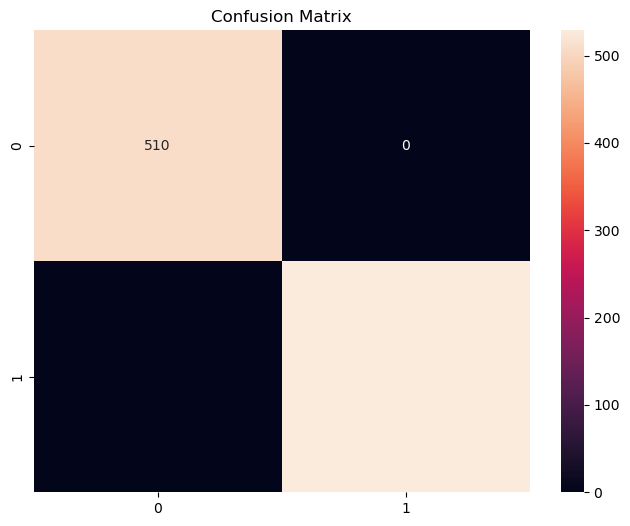

In [57]:
# Compute confusion matrix
cm = confusion_matrix(y_train, y_fr_train_pred)

# Set up the heatmap
plt.figure(figsize=(8, 6))
sb.heatmap(cm, annot=True, fmt="d")

# Add title
plt.title('Confusion Matrix')

# Display the plot
plt.show()

In [58]:
y_fr_test_pred = forest.predict(X_test_dtm)

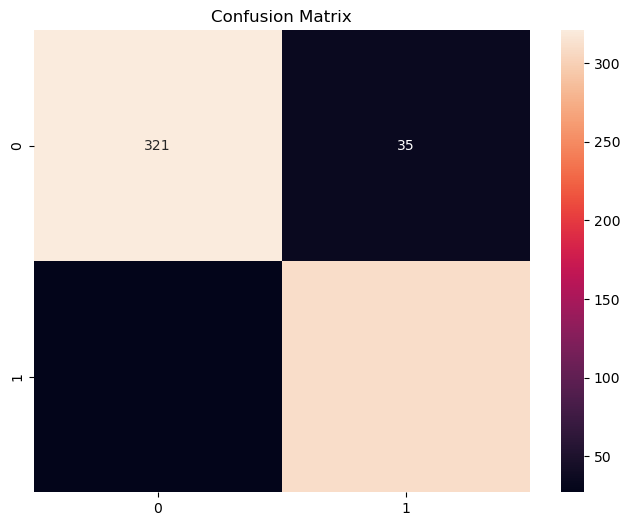

In [59]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_fr_test_pred)

# Set up the heatmap
plt.figure(figsize=(8, 6))
sb.heatmap(cm, annot=True, fmt="d")

# Add title
plt.title('Confusion Matrix')

# Display the plot
plt.show()

In [60]:
# Results of the Random Forest Classification

print("Random Forest Accuracy:", accuracy_score(y_test, y_fr_test_pred))
print("Random Forest F2 score:", fbeta_score(y_test, y_fr_test_pred, average='binary', beta=2))
print('Random Forest ROC AUC Score', roc_auc_score(y_test, y_fr_test_pred))

Random Forest Accuracy: 0.9105339105339105
Random Forest F2 score: 0.9155345540460721
Random Forest ROC AUC Score 0.9107833494482046


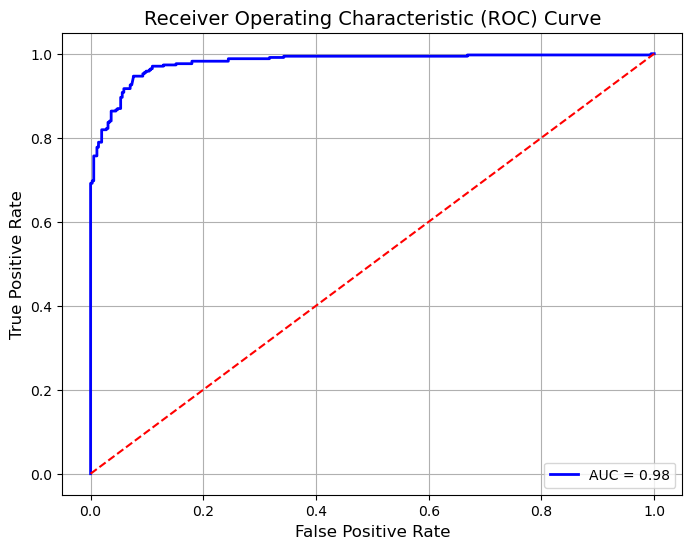

In [61]:
# Calculate ROC curve
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred_proba)

# Calculate AUC
auc = metrics.roc_auc_score(y_test, y_pred_proba)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='b', lw=2, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], color='r', linestyle='--')  # Diagonal line for random classifier
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True)
plt.show()

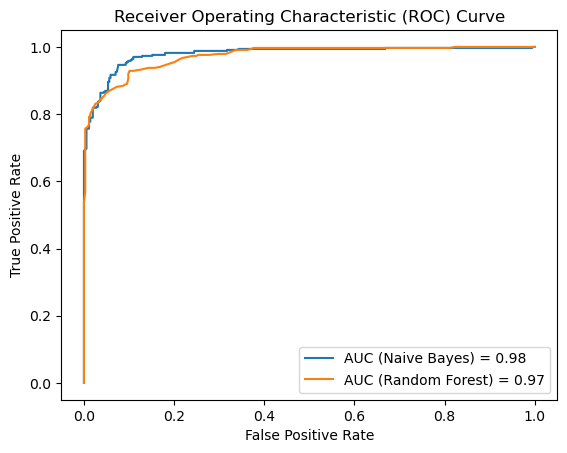

In [62]:
# Comparison of both ROC graphs
# Calculate ROC curve and AUC for Naive Bayes
y_pred_proba_nb = nb.predict_proba(X_test_dtm)[:, 1]
fpr_nb, tpr_nb, _ = metrics.roc_curve(y_test, y_pred_proba_nb)
auc_nb = metrics.roc_auc_score(y_test, y_pred_proba_nb)
plt.plot(fpr_nb, tpr_nb, label=f"AUC (Naive Bayes) = {auc_nb:.2f}")

# Calculate ROC curve and AUC for Random Forest
y_pred_proba_rf = forest.predict_proba(X_test_dtm)[:, 1]
fpr_rf, tpr_rf, _ = metrics.roc_curve(y_test, y_pred_proba_rf)
auc_rf = metrics.roc_auc_score(y_test, y_pred_proba_rf)
plt.plot(fpr_rf, tpr_rf, label=f"AUC (Random Forest) = {auc_rf:.2f}")

# Set labels and legend
plt.xlabel("False Positive Rate", size=10)
plt.ylabel("True Positive Rate", size=10)
plt.legend(loc="lower right")
plt.title("Receiver Operating Characteristic (ROC) Curve")

# Display the plot
plt.show()